In [1]:
# Import the tools for data loading and model comparison.
from pathlib import Path
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from pycaret.classification import ClassificationExperiment

print("Ready to compare classification models.")

Ready to compare classification models.


In [2]:
# Locate the dataset relative to the notebooks folder.
data_path = Path("../data/raw/diabetic_data.csv")

# Treat "?" as missing, while preserving the literal category "None".
df = pd.read_csv(
    data_path,
    keep_default_na=False,
    na_values=["?"]
)

# Define the target: 1 = readmitted within 30 days; 0 = otherwise.
df["early_readmission"] = df["readmitted"].map({
    "<30": 1,
    ">30": 0,
    "NO": 0
})

# Stop if any readmission category could not be mapped.
assert df["early_readmission"].notna().all(), "Unexpected readmission category."

print("Dataset shape:", df.shape)
print("\nTarget counts:")
print(df["early_readmission"].value_counts().sort_index())

Dataset shape: (101766, 51)

Target counts:
early_readmission
0    90409
1    11357
Name: count, dtype: int64


In [3]:
# Split by patient to keep each person's visits in one partition.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        df,
        y=df["early_readmission"],
        groups=df["patient_nbr"]
    )
)

train_data = df.iloc[train_idx].copy()
test_data = df.iloc[test_idx].copy()

# Verify that no patient appears in both partitions.
shared_patients = set(train_data["patient_nbr"]) & set(
    test_data["patient_nbr"]
)
assert len(shared_patients) == 0, "Patient overlap detected."

print("Training encounters:", len(train_data))
print("Test encounters:", len(test_data))
print("Shared patients:", len(shared_patients))

Training encounters: 81613
Test encounters: 20153
Shared patients: 0


In [4]:
# Keep patient IDs separately for grouped cross-validation.
train_groups = train_data["patient_nbr"].reset_index(drop=True)

# Remove identifiers, the original outcome, and mostly missing weight.
excluded_columns = [
    "encounter_id",
    "patient_nbr",
    "readmitted",
    "weight"
]

train_model = train_data.drop(columns=excluded_columns).reset_index(drop=True)
test_model = test_data.drop(columns=excluded_columns).reset_index(drop=True)

# Identify constant predictors using training data only.
constant_columns = [
    column
    for column in train_model.columns
    if column != "early_readmission"
    and train_model[column].nunique(dropna=False) <= 1
]

# Apply the same column removal to both partitions.
train_model = train_model.drop(columns=constant_columns)
test_model = test_model.drop(columns=constant_columns)

print("Constant columns removed:", constant_columns)
print("Predictors:", train_model.shape[1] - 1)

Constant columns removed: ['acetohexamide', 'examide', 'citoglipton', 'metformin-pioglitazone']
Predictors: 42


In [5]:
# These variables represent numerical quantities.
numeric_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

# All remaining predictors represent categories.
categorical_features = [
    column
    for column in train_model.columns
    if column not in numeric_features + ["early_readmission"]
]

print("Numerical predictors:", len(numeric_features))
print("Categorical predictors:", len(categorical_features))

Numerical predictors: 8
Categorical predictors: 34


In [10]:
# Create a classification experiment.
experiment = ClassificationExperiment()

# Configure preprocessing and patient-grouped cross-validation.
experiment.setup(
    data=train_model,
    test_data=test_model,
        index=False,
    target="early_readmission",
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    numeric_imputation="median",
    categorical_imputation="constant",
    normalize=True,
    fold_strategy="groupkfold",
    fold_groups=train_groups,
    fold=3,
    session_id=42,
    n_jobs=1,
    verbose=True
)

,Description,Value
0,Session id,42
1,Target,early_readmission
2,Target type,Binary
3,Original data shape,"(101766, 43)"
4,Transformed data shape,"(101766, 143)"
5,Transformed train set shape,"(81613, 143)"
6,Transformed test set shape,"(20153, 143)"
7,Numeric features,8
8,Categorical features,34
9,Rows with missing values,73.7%


In [11]:
# Compare five models and select the highest cross-validation AUC.
best_model = experiment.compare_models(
    include=["lr", "dt", "rf", "et", "lightgbm"],
    sort="AUC",
    n_select=1,
    errors="raise"
)

# Save and display the comparison results.
comparison_results = experiment.pull()
display(comparison_results)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
lightgbm,Light Gradient Boosting Machine,0.8870,0.6696,0.0201,0.4797,0.0386,0.0298,0.0798,3.4667
lr,Logistic Regression,0.8864,0.6651,0.0274,0.4486,0.0516,0.0390,0.0879,3.3300
rf,Random Forest Classifier,0.8873,0.6456,0.0021,0.5940,0.0041,0.0033,0.0299,8.9100
et,Extra Trees Classifier,0.8870,0.6308,0.0027,0.3813,0.0054,0.0039,0.0242,10.1133
dt,Decision Tree Classifier,0.8002,0.5309,0.1832,0.1610,0.1714,0.0583,0.0585,3.2167


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
lightgbm,Light Gradient Boosting Machine,0.8870,0.6696,0.0201,0.4797,0.0386,0.0298,0.0798,3.4667
lr,Logistic Regression,0.8864,0.6651,0.0274,0.4486,0.0516,0.0390,0.0879,3.3300
rf,Random Forest Classifier,0.8873,0.6456,0.0021,0.5940,0.0041,0.0033,0.0299,8.9100
et,Extra Trees Classifier,0.8870,0.6308,0.0027,0.3813,0.0054,0.0039,0.0242,10.1133
dt,Decision Tree Classifier,0.8002,0.5309,0.1832,0.1610,0.1714,0.0583,0.0585,3.2167


In [12]:
# Give both classes equal total weight during training.
# Evaluate with the same patient-grouped cross-validation.
balanced_lightgbm = experiment.create_model(
    "lightgbm",
    class_weight="balanced"
)

# Save and display the validation results.
balanced_results = experiment.pull()
display(balanced_results)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6694,0.6671,0.5484,0.1812,0.2724,0.1237,0.1556
1,0.6708,0.6649,0.5464,0.1796,0.2703,0.1230,0.1549
2,0.6726,0.6699,0.5579,0.1866,0.2797,0.1314,0.1644
Mean,0.6709,0.6673,0.5509,0.1825,0.2741,0.1260,0.1583
Std,0.0013,0.0020,0.0050,0.0030,0.0040,0.0038,0.0044


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6694,0.6671,0.5484,0.1812,0.2724,0.1237,0.1556
1,0.6708,0.6649,0.5464,0.1796,0.2703,0.1230,0.1549
2,0.6726,0.6699,0.5579,0.1866,0.2797,0.1314,0.1644
Mean,0.6709,0.6673,0.5509,0.1825,0.2741,0.1260,0.1583
Std,0.0013,0.0020,0.0050,0.0030,0.0040,0.0038,0.0044


In [13]:
# Compare both configurations using cross-validation results.
balance_comparison = pd.DataFrame({
    "Original LightGBM": comparison_results.loc[
        "lightgbm", ["AUC", "Recall", "Prec.", "F1"]
    ],
    "Balanced LightGBM": balanced_results.loc[
        "Mean", ["AUC", "Recall", "Prec.", "F1"]
    ]
}).T

display(balance_comparison.round(4))

,AUC,Recall,Prec.,F1
Original LightGBM,0.6696,0.0201,0.4797,0.0386
Balanced LightGBM,0.6673,0.5509,0.1825,0.2741


In [14]:
# Evaluate the balanced model on the reserved test partition.
# Keep the classification threshold fixed at 0.50.
test_predictions = experiment.predict_model(
    balanced_lightgbm,
    probability_threshold=0.50
)

# Store and display the test metrics.
test_results = experiment.pull()
display(test_results)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Light Gradient Boosting Machine,0.6652,0.6759,0.5700,0.1739,0.2665,0.1231,0.1596


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Light Gradient Boosting Machine,0.6652,0.6759,0.57,0.1739,0.2665,0.1231,0.1596


In [16]:
from sklearn.metrics import confusion_matrix

# Count correct predictions, false alarms, and missed readmissions.
tn, fp, fn, tp = confusion_matrix(
    test_predictions["early_readmission"],
    test_predictions["prediction_label"],
    labels=[0, 1]
).ravel()

print("Correctly predicted no early readmission:", tn)
print("False alarms:", fp)
print("Missed early readmissions:", fn)
print("Detected early readmissions:", tp)

Correctly predicted no early readmission: 12179
False alarms: 5823
Missed early readmissions: 925
Detected early readmissions: 1226


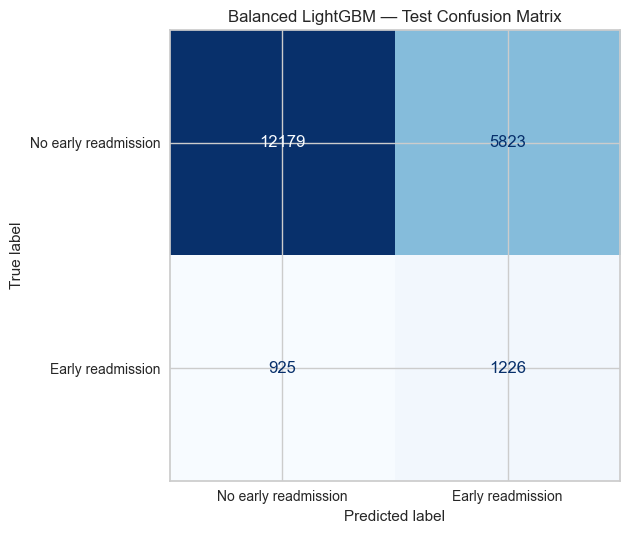

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Plot the test results: rows = actual, columns = predicted.
ConfusionMatrixDisplay.from_predictions(
    test_predictions["early_readmission"],
    test_predictions["prediction_label"],
    labels=[0, 1],
    display_labels=["No early readmission", "Early readmission"],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Balanced LightGBM — Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
### Balanced LightGBM: test results

At a classification threshold of 0.50, balanced LightGBM achieved
a test ROC AUC of 0.6759, recall of 57.00%, and precision of 17.39%.

The model detected 1,226 of 2,151 early readmissions, missed 925,
and generated 5,823 false alerts.

Class weighting increased recall compared with the original
configuration in cross-validation, but reduced precision.
The high number of false alerts remains a major limitation.
These exploratory results do not establish clinical usefulness.